# 시크릿 이력 정리와 예방

**이 노트북에서 할 일**

1. 04절처럼 임시 폴더에 팀 원격 저장소와 작성자·리뷰어 저장소를 만듭니다.
2. 무시 규칙과 커밋 전 비교 읽기로 더미 키가 커밋에 들어가지 않게 막아 봅니다.
3. 커밋에 들어간 더미 키를 추적 해제와 이력 재작성으로 각각 치워 보고 결과를 비교합니다.

**준비물** — API 키 불필요. 실제 비밀 값은 쓰지 않습니다. 어디에서도 쓸 수 없는 더미 문자열 `DEMO-ONLY-NOT-A-REAL-SECRET`만 씁니다.
모델 호출은 0번이고 비용은 들지 않습니다. 실행 시간은 1분 이내입니다.

**기준 Git 버전** — Git은 2.28 이상이 필요하고, 교재 출력은 Git 2.34.1로 만들었습니다.
이력 정리 도구 설명서는 Git 2.36.0 이상을 요구 사항으로 적어 두었으므로, 새로 설치한다면 2.36 이상을 권합니다.
이 노트북이 쓰는 옵션은 Git 2.34.1에서도 끝까지 실행됐습니다.

실습 폴더 `labs/part1/ch03-git-github`에서 `uv sync --locked`로 만든 `.venv`를 커널로 고릅니다.
이 가상환경에 이력 정리 도구 `git-filter-repo` 2.47.0이 들어 있습니다. 첫 셀부터 순서대로 실행하고, GitHub 계정과 네트워크는 쓰지 않습니다.

## 오늘 볼 그림

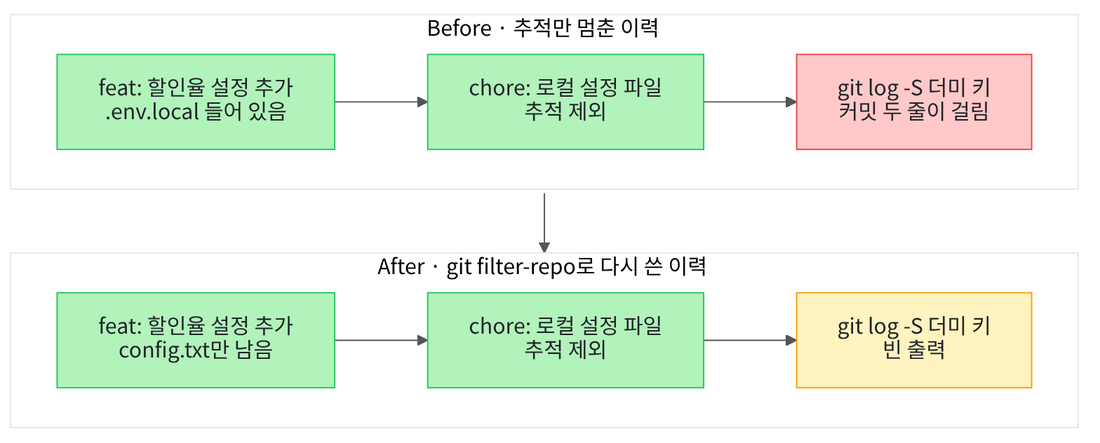

위 칸이 Before, 아래 칸이 After이고 칸마다 왼쪽에서 오른쪽으로 읽습니다. 초록 상자는 커밋입니다.
Before 칸은 추적을 멈춘 커밋을 더했을 뿐이라, 더미 키 검색에 커밋 두 줄이 걸립니다. After 칸은 이력을 다시 써서 같은 검색이 빈 출력입니다.

## 1. 준비

이 절도 설치할 패키지가 없습니다. 이력 정리 도구는 실습 폴더의 `.venv`에 이미 들어 있습니다.
04절처럼 빈 임시 폴더를 만들고 그 폴더로 작업 위치를 옮깁니다. 폴더 이름의 앞머리만 `ch03-05-`로 바꿨습니다.

앞에서 배운 함수는 `git_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
이 노트북은 03·04절처럼 02절 `run_git()`을 가져옵니다.

가져오는 줄은 작업 위치를 옮기기 전에 둡니다. 도구 파일을 현재 작업 폴더에서 찾기 때문입니다.

In [1]:
# 02절 run_git()을 도구 파일에서 가져오고, 저장소들을 담을 빈 임시 폴더로 작업 위치를 옮깁니다
import os
import tempfile

# 작업 위치를 옮기기 전에 가져옵니다. 도구 파일은 노트북과 같은 폴더에 있습니다
from git_tools import run_git

# mkdtemp()는 운영체제 임시 폴더 안에 새 폴더를 만들고 그 경로를 반환합니다
practice_folder = tempfile.mkdtemp(prefix="ch03-05-")
os.chdir(practice_folder)
file_names = os.listdir()
print("현재 작업 폴더의 파일:", file_names)

현재 작업 폴더의 파일: []


**결과 읽기** — 현재 작업 폴더의 파일은 `[]`로, 빈 폴더에서 시작합니다.

## 2. 가져온 git 명령 함수

1번 준비 셀에서 가져온 `run_git()`은 02절에서 만든 함수입니다. 두 번째 매개변수 `folder`는 명령을 실행할 폴더이고, 기본값 `"."`은 현재 작업 폴더입니다.
git 명령이 실패해도 셀은 멈추지 않고 종료 코드 줄을 보여 줍니다.

## 3. 팀 원격 저장소와 무시 규칙

04절과 같은 순서로 원격 저장소 `team.git`을 만들고, 작성자가 `author` 폴더로 복제합니다.
작성자 정보도 04절과 같은 `Ch3 Student`를 이 저장소에만 적습니다.

실행 전에 예상합니다. 빈 저장소를 복제했다는 경고가 한 번 나오고, 종료 코드 줄은 없을 것입니다.

In [2]:
# 팀 원격 저장소를 만들고, 작성자가 복제한 저장소에 이름과 전자우편 주소를 적습니다
run_git("init --bare -b main team.git")
run_git("clone team.git author")
run_git('config user.name "Ch3 Student"', "author")
run_git("config user.email student@example.com", "author")

. $ git init --bare -b main team.git
Initialized empty Git repository in [사용자 폴더]/tmp/ch03-05-ji6wd5tm/team.git/

. $ git clone team.git author
Cloning into 'author'...
done.

author $ git config user.name "Ch3 Student"

author $ git config user.email student@example.com



**결과 읽기** — 줄 `Initialized empty Git repository`로 원격 저장소가 생겼습니다.
경고 `You appear to have cloned an empty repository`는 04절에서도 본 안내입니다. 종료 코드 줄이 없으므로 네 명령 모두 성공했습니다.
경로 앞 `[사용자 폴더]`는 실행 도구가 사용자 폴더 이름을 가린 표시입니다.

작성자가 01절과 같은 무시 규칙 세 줄을 `.gitignore`에 적어 첫 커밋으로 올립니다.
첫 줄 `.env`는 비밀 값을 적어 두는 환경 파일의 이름입니다. 여러 줄 글은 01절처럼 `"""`로 적습니다.

실행 전에 예상합니다. 첫 커밋 표시와 새 브랜치 표시가 나올 것입니다.

In [3]:
# 작성자가 01절의 무시 규칙 세 줄을 첫 커밋으로 기록하고 원격에 올립니다
ignore_text = """.env
__pycache__/
*.log
"""
with open("author/.gitignore", "w", encoding="utf-8") as file:
    file.write(ignore_text)
run_git("add .gitignore", "author")
run_git('commit -m "chore: 환경 파일 추적 제외"', "author")
run_git("push -u origin main", "author")

author $ git add .gitignore

author $ git commit -m "chore: 환경 파일 추적 제외"
[main (root-commit) 47367f7] chore: 환경 파일 추적 제외
 1 file changed, 3 insertions(+)
 create mode 100644 .gitignore

author $ git push -u origin main
Branch 'main' set up to track remote branch 'main' from 'origin'.
To [사용자 폴더]/tmp/ch03-05-ji6wd5tm/team.git
 * [new branch]      main -> main



**결과 읽기** — 표시 `main (root-commit)`은 main 브랜치의 첫 커밋이라는 뜻입니다. 요약 줄은 `1 file changed, 3 insertions(+)`입니다.
올리기 출력의 `[new branch]`로 원격 저장소에도 main이 생겼습니다.

## 4. 예방 1 — 무시 규칙으로 .env 막기

시크릿(secret)은 API 키나 비밀번호처럼, 가진 사람에게 권한을 주는 값입니다. 복사해도 문이 열리는 집 열쇠와 같습니다.
이 절에서는 어디에서도 쓸 수 없는 더미 문자열을 시크릿 대신 씁니다.

변수 `dummy_key`에 더미 문자열을 담고, 환경 파일 `.env`에 `DEMO_API_KEY=` 뒤에 붙여 적습니다. 글자 사이 `+`는 01절에서 본 이어 붙이기입니다.
명령 `git status --short --ignored`와 `git check-ignore -v`도 01절에서 배웠습니다.

실행 전에 예상합니다. 상태 표시에 무시한 파일이 나오고, 걸린 규칙은 `.gitignore`의 첫 줄일 것입니다.

In [4]:
# 쓸 수 없는 더미 키를 .env에 적고, git이 이 파일을 무시하는지 확인합니다
dummy_key = "DEMO-ONLY-NOT-A-REAL-SECRET"
with open("author/.env", "w", encoding="utf-8") as file:
    file.write("DEMO_API_KEY=" + dummy_key + "\n")
run_git("status --short --ignored", "author")
run_git("check-ignore -v .env", "author")

author $ git status --short --ignored
!! .env

author $ git check-ignore -v .env
.gitignore:1:.env	.env



**결과 읽기** — 상태 표시는 `!! .env` 한 줄입니다. 추적하지 않는 새 파일 `??`가 아니라 무시한 파일로 봅니다.
줄 `.gitignore:1:.env`는 `.gitignore` 파일 첫 줄의 규칙 `.env`에 걸렸다는 뜻입니다.

## 5. 예방 2 — 커밋 전에 색인 비교 읽기

팀원에게는 어떤 설정 이름이 필요한지 알려야 합니다. 그래서 값 자리에 `replace-me`만 적은 예시 파일 `settings.example`을 커밋합니다.
커밋하기 전에 01절의 `git diff --cached`로 색인에 올린 변경을 읽습니다. 이번 커밋에 실제로 들어갈 내용입니다.

실행 전에 예상합니다. 비교 출력의 더하기 줄은 하나이고, 더미 키는 보이지 않을 것입니다.

In [5]:
# 값 자리를 비운 예시 파일을 색인에 올리고, 커밋 전에 들어갈 내용을 읽은 뒤 올립니다
with open("author/settings.example", "w", encoding="utf-8") as file:
    file.write("DEMO_API_KEY=replace-me\n")
run_git("add settings.example", "author")
run_git("diff --cached", "author")
run_git('commit -m "docs: 설정 예시 추가"', "author")
run_git("push", "author")

author $ git add settings.example

author $ git diff --cached
diff --git a/settings.example b/settings.example
new file mode 100644
index 0000000..02e3d73
--- /dev/null
+++ b/settings.example
@@ -0,0 +1 @@
+DEMO_API_KEY=replace-me

author $ git commit -m "docs: 설정 예시 추가"
[main 33f8b58] docs: 설정 예시 추가
 1 file changed, 1 insertion(+)
 create mode 100644 settings.example

author $ git push
To [사용자 폴더]/tmp/ch03-05-ji6wd5tm/team.git
   47367f7..33f8b58  main -> main



**결과 읽기** — 비교 출력의 `new file mode 100644`는 새 파일이라는 뜻입니다. 더하기 줄은 `+DEMO_API_KEY=replace-me` 하나이고 더미 키가 없습니다.
커밋 뒤 올리기 출력은 `main -> main`입니다.

이 확인은 사람이 출력을 읽는 단계입니다. 읽지 않고 커밋하면 막아 주지 못합니다.

## 6. 값 하나 바꿔 보기 — 파일 이름을 .env.local로

4번에서는 환경 파일 이름이 `.env`였습니다. 이번에는 이름만 `.env.local`로 바꿔 같은 내용을 적습니다.
별표 없는 규칙 `.env`는 이름이 정확히 같은 파일에만 걸립니다. 별표 `*`의 뜻은 01절에서 배웠습니다.

실행 전에 예상합니다. 새 파일은 무시한 파일이 아니라 추적하지 않는 파일로 보이고, 걸린 규칙이 없을 것입니다.

In [6]:
# 같은 더미 키를 이름만 다른 .env.local에 적고, 무시 규칙에 걸리는지 확인합니다
with open("author/.env.local", "w", encoding="utf-8") as file:
    file.write("DEMO_API_KEY=" + dummy_key + "\n")
run_git("status --short --ignored", "author")
run_git("check-ignore -v .env.local", "author")

author $ git status --short --ignored
?? .env.local
!! .env

author $ git check-ignore -v .env.local

종료 코드: 1


**결과 읽기** — 상태 표시에 `?? .env.local`과 `!! .env`가 함께 나옵니다. 걸린 규칙을 묻는 명령은 빈 출력 뒤 `종료 코드: 1`을 보였습니다.
01절에서 본 것처럼 종료 코드 1은 걸린 규칙이 없다는 뜻입니다.

이름 하나가 달라지자 무시 규칙이 막지 못했습니다. 이 파일은 지우지 않고 다음 Before에서 그대로 씁니다.

## 7. Before — 추적만 멈추고 끝내기

작성자가 할인율 설정 파일 `config.txt`를 만들어 서둘러 올립니다. 할인율 10은 04절에서 쓴 값입니다.
이번에는 파일 이름 대신 `git add .`을 씁니다. 이 명령은 지금 폴더의 변경을 한꺼번에 색인에 올리며, 01절에서는 이름만 봤습니다.

실행 전에 예상합니다. 무시한 `.env`는 빠지고, 6번의 `.env.local`은 함께 올라갈 것입니다.

In [7]:
# Before: 설정 파일을 만들고 폴더 전체를 색인에 올려 커밋하고 원격에 올립니다
with open("author/config.txt", "w", encoding="utf-8") as file:
    file.write("discount=10\n")
run_git("add .", "author")
run_git("status --short", "author")
run_git('commit -m "feat: 할인율 설정 추가"', "author")
run_git("push", "author")

author $ git add .

author $ git status --short
A  .env.local
A  config.txt

author $ git commit -m "feat: 할인율 설정 추가"
[main 7929e7b] feat: 할인율 설정 추가
 2 files changed, 2 insertions(+)
 create mode 100644 .env.local
 create mode 100644 config.txt

author $ git push
To [사용자 폴더]/tmp/ch03-05-ji6wd5tm/team.git
   33f8b58..7929e7b  main -> main



**결과 읽기** — 상태 표시는 `A  .env.local`과 `A  config.txt` 두 줄입니다. 커밋 출력에도 `create mode 100644 .env.local`이 있습니다.
올리기는 `main -> main`으로 성공했습니다.

작성자는 상태 표시를 읽지 않고 커밋했습니다. 더미 키가 든 파일이 원격까지 올라갔습니다.

리뷰어가 원격 저장소를 복제합니다. 폴더 이름은 04절과 같은 `reviewer`입니다.
이번에는 리뷰어가 커밋하지 않으므로 이름과 전자우편 주소는 적지 않습니다.

실행 전에 예상합니다. 리뷰어 폴더에도 `.env.local`이 있을 것입니다.

In [8]:
# Before: 리뷰어가 원격을 복제하고, 받은 폴더의 파일 목록을 봅니다
run_git("clone team.git reviewer")
file_names = os.listdir("reviewer")
print("리뷰어 폴더의 파일:", sorted(file_names))

. $ git clone team.git reviewer
Cloning into 'reviewer'...
done.

리뷰어 폴더의 파일: ['.env.local', '.git', '.gitignore', 'config.txt', 'settings.example']


**결과 읽기** — 리뷰어 폴더의 파일은 `['.env.local', '.git', '.gitignore', 'config.txt', 'settings.example']`입니다.
작성자가 올린 더미 키 파일이 리뷰어 폴더에도 들어왔습니다.

작성자가 실수를 알아채고 01절에서 배운 방법으로 고칩니다. 무시 규칙 파일 끝에 `.env.local` 줄을 더합니다.
명령 `git rm --cached`로 색인에서만 빼서 커밋하고 올립니다. 파일 끝에 덧붙이는 모드 `"a"`도 01절에서 썼습니다.

실행 전에 예상합니다. 두 환경 파일이 모두 무시한 파일로 보일 것입니다.

In [9]:
# Before: 무시 규칙에 .env.local을 더하고, 색인에서만 빼서 커밋하고 올립니다
with open("author/.gitignore", "a", encoding="utf-8") as file:
    file.write(".env.local\n")
run_git("rm --cached .env.local", "author")
run_git("add .gitignore", "author")
run_git('commit -m "chore: 로컬 설정 파일 추적 제외"', "author")
run_git("push", "author")
run_git("status --short --ignored", "author")

author $ git rm --cached .env.local
rm '.env.local'

author $ git add .gitignore

author $ git commit -m "chore: 로컬 설정 파일 추적 제외"
[main 6eebd11] chore: 로컬 설정 파일 추적 제외
 2 files changed, 1 insertion(+), 1 deletion(-)
 delete mode 100644 .env.local

author $ git push
To [사용자 폴더]/tmp/ch03-05-ji6wd5tm/team.git
   7929e7b..6eebd11  main -> main

author $ git status --short --ignored
!! .env
!! .env.local



**결과 읽기** — 커밋 출력의 `delete mode 100644 .env.local`로 이 커밋에서 파일 추적을 멈췄습니다.
마지막 상태 표시는 `!! .env`와 `!! .env.local`입니다.

지금 커밋만 보면 더미 키가 없습니다. 지난 커밋에는 어떤지 다음 셀에서 확인합니다.

지난 커밋에 더미 키가 남았는지 두 방법으로 봅니다.
명령 `git log -S 글자`는 그 글자를 넣거나 뺀 커밋만 보여 줍니다. 옵션 `--all`은 지금 브랜치만이 아니라 모든 브랜치와 원격 이름에서 찾으라는 뜻입니다.
01절에서 쓴 `git show HEAD~1:파일`로 바로 앞 커밋의 파일도 읽습니다.

실행 전에 예상합니다. 더미 키를 넣은 커밋과 뺀 커밋 두 줄이 나오고, 파일 내용에 더미 키가 보일 것입니다.

In [10]:
# Before: 이력 전체에서 더미 키를 넣거나 뺀 커밋을 찾고, 바로 앞 커밋의 파일을 읽습니다
run_git("log --oneline --all -S " + dummy_key, "author")
run_git("show HEAD~1:.env.local", "author")

author $ git log --oneline --all -S DEMO-ONLY-NOT-A-REAL-SECRET
6eebd11 chore: 로컬 설정 파일 추적 제외
7929e7b feat: 할인율 설정 추가

author $ git show HEAD~1:.env.local
DEMO_API_KEY=DEMO-ONLY-NOT-A-REAL-SECRET



**결과 읽기** — 검색 결과는 `chore: 로컬 설정 파일 추적 제외`와 `feat: 할인율 설정 추가` 두 줄입니다.
앞 커밋의 파일은 `DEMO_API_KEY=DEMO-ONLY-NOT-A-REAL-SECRET`입니다.

추적을 멈춘 커밋을 더해도 지난 커밋에는 더미 키가 그대로 있습니다. 이 커밋은 원격과 리뷰어 폴더에도 있습니다.

## 8. After — 먼저 할 일과 이력 다시 쓰기

실제 키였다면 가장 먼저 키를 발급한 서비스에서 그 키를 폐기(revoke)하거나 새 키로 교체(rotate)합니다.
이미 복사된 키가 있어도 더는 쓸 수 없게 하려는 것입니다. 더미 키라서 이 단계는 이번에 실행하지 않았습니다.

그다음 이력 재작성(history rewriting)으로 지난 커밋에서 파일을 뺍니다. 조건에 맞춰 커밋을 새로 만들어 이력을 다시 세우는 작업입니다.
이 절은 도구 `git-filter-repo`를 씁니다.

이 도구는 git에 들어 있지 않고, 실습 폴더의 `.venv`에 따로 설치한 Python 프로그램입니다.
설치 문서에 따르면 명령을 찾아볼 폴더 목록(PATH)에 프로그램이 있어야 `git filter-repo`로 줄여 부를 수 있습니다.
교재를 만들 때 가상환경을 켜지 않은 Python에서 이렇게 부르자 `git: 'filter-repo' is not a git command`가 나왔습니다.

그래서 이 커널의 Python으로 도구를 직접 실행하는 함수 `run_filter_repo()`를 만듭니다. 뼈대는 02절의 `run_python()`과 같습니다.
이름 `sys.executable`은 지금 커널의 Python 경로이고, 옵션 `-m`은 Ch 2 08절 `run_pytest()`처럼 모듈을 프로그램으로 실행합니다.
옵션 글은 `shlex.split()`으로 낱말로 나눈 뒤, Ch 2 03절처럼 `for`와 `append()`로 목록 끝에 붙입니다.

모듈 shlex·subprocess·sys는 이 셀에서 불러옵니다. 도구 파일에서 가져온 것은 함수 `run_git()` 하나뿐입니다.
실행 전에 예상합니다. 정의 셀이라 출력은 없을 것입니다.

In [11]:
# git-filter-repo 모듈을 이 커널의 Python으로 실행하고, 폴더와 명령, 출력을 보여 주는 함수
import shlex
import subprocess
import sys


def run_filter_repo(options: str, folder: str):
    arguments = [sys.executable, "-m", "git_filter_repo"]
    # 옵션 글을 낱말로 나눠 목록 끝에 하나씩 붙입니다
    for word in shlex.split(options):
        arguments.append(word)
    result = subprocess.run(arguments, capture_output=True, encoding="utf-8", cwd=folder)
    print(folder, "$ python -m git_filter_repo", options)
    print(result.stdout + result.stderr)
    if result.returncode != 0:
        print("종료 코드:", result.returncode)

**결과 읽기** — 예상대로 출력이 없습니다. 함수를 새로 정의하기만 했습니다.

도구 설명서는 되돌릴 수 없는 작업이라 막 복제한 저장소에서 실행하라고 안내합니다. 같은 컴퓨터의 폴더를 복제할 때는 옵션 `--no-local`을 붙이라고 적혀 있습니다.
그래서 작성자는 옛 `author` 폴더 대신 새 복제본 `author-clean`에서 작업합니다.

도구 옵션 `--path .env.local`은 이 경로를 고르고, `--invert-paths`는 고른 것을 거꾸로 해 그 경로만 뺍니다.
실행 전에 예상합니다. 도구가 커밋 네 개를 읽고 새 이력을 썼다는 안내가 나올 것입니다.

In [12]:
# After: 원격을 새로 복제하고, 모든 커밋에서 .env.local 경로를 뺀 이력을 새로 씁니다
run_git("clone --no-local team.git author-clean")
run_filter_repo("--invert-paths --path .env.local", "author-clean")

. $ git clone --no-local team.git author-clean
Cloning into 'author-clean'...

author-clean $ python -m git_filter_repo --invert-paths --path .env.local
NOTICE: Removing 'origin' remote; see 'Why is my origin removed?'
        in the manual if you want to push back there.
        (was [사용자 폴더]/tmp/ch03-05-ji6wd5tm/team.git)

Parsed 4 commitsHEAD is now at 3fb2734 chore: 로컬 설정 파일 추적 제외

New history written in 0.01 seconds; now repacking/cleaning...
Repacking your repo and cleaning out old unneeded objects
Completely finished after 0.02 seconds.



**결과 읽기** — 줄 `Parsed 4 commits`는 커밋 네 개를 읽었다는 뜻이고, 줄 `New history written`으로 새 이력을 썼습니다.
줄 `NOTICE: Removing 'origin' remote`는 도구가 원격 이름 origin을 지웠다는 안내입니다.

도구 설명서에 따르면 옛 이력과 새 이력이 섞이지 않게 일부러 지웁니다. 초 단위 시간과 임시 경로는 실행마다 달라 읽지 않습니다.

새 이력의 커밋 목록을 보고, Before와 같은 방법으로 더미 키를 검색합니다.

실행 전에 예상합니다. 커밋 목록은 네 줄이고, 더미 키 검색은 빈 출력일 것입니다.

In [13]:
# After: 새 이력의 커밋 목록을 보고, Before와 같은 방법으로 더미 키를 검색합니다
run_git("log --oneline", "author-clean")
run_git("log --oneline --all -S " + dummy_key, "author-clean")

author-clean $ git log --oneline
3fb2734 chore: 로컬 설정 파일 추적 제외
e66613a feat: 할인율 설정 추가
33f8b58 docs: 설정 예시 추가
47367f7 chore: 환경 파일 추적 제외

author-clean $ git log --oneline --all -S DEMO-ONLY-NOT-A-REAL-SECRET



**결과 읽기** — 커밋 목록은 `feat: 할인율 설정 추가`를 포함한 네 줄로, 메시지는 Before와 같습니다.
더미 키 검색은 명령 줄 아래가 비어 있고 종료 코드 줄도 없습니다.

위 두 커밋의 해시는 Before 검색에 나온 해시와 다릅니다. 파일 목록이 바뀐 커밋과 그 뒤 커밋은 새 커밋이 되기 때문입니다.

원격 이름을 다시 적고 새 이력을 올립니다. 명령 `git remote add origin ../team.git`은 원격 이름 origin에 그 경로를 적습니다.

원격 main에는 새 이력에 없는 옛 커밋이 있습니다. 03절에서 본 것처럼 이런 올리기는 거절되므로 옵션 `--force`를 붙입니다.
이 옵션은 원격 main을 이 커밋으로 강제로 옮깁니다. 03·04절에서는 이름만 봤고 이번에 처음 실행합니다.

실행 전에 예상합니다. 거절 표시 대신 강제로 바꿨다는 표시가 나올 것입니다.

In [14]:
# After: 도구가 지운 원격 이름을 다시 적고, 새 이력으로 원격 main을 강제로 바꿉니다
run_git("remote add origin ../team.git", "author-clean")
run_git("push --force origin main", "author-clean")

author-clean $ git remote add origin ../team.git

author-clean $ git push --force origin main
To ../team.git
 + 6eebd11...3fb2734 main -> main (forced update)



**결과 읽기** — 원격 이름을 적은 명령은 출력이 없습니다. 올리기 출력 끝은 `main -> main (forced update)`이고, 줄 앞에 더하기 표시가 붙었습니다.
원격 main이 새 이력으로 바뀌었습니다.

리뷰어 폴더는 Before에서 옛 이력을 복제했습니다. 02절의 `git fetch`로 원격 이름만 옮기고, `git branch -vv`로 짝과 비교합니다.
같은 더미 키 검색도 합니다.

실행 전에 예상합니다. 받아 온 출력에 강제로 바뀐 표시가 있고, 리뷰어 main에는 더미 키 커밋이 남아 있을 것입니다.

In [15]:
# After: 리뷰어의 옛 복제본에서 원격 변경을 받아 오고, 짝 비교와 더미 키 검색을 합니다
run_git("fetch", "reviewer")
run_git("branch -vv", "reviewer")
run_git("log --oneline --all -S " + dummy_key, "reviewer")

reviewer $ git fetch
From [사용자 폴더]/tmp/ch03-05-ji6wd5tm/team
 + 7929e7b...3fb2734 main       -> origin/main  (forced update)

reviewer $ git branch -vv
* main 7929e7b [origin/main: ahead 1, behind 2] feat: 할인율 설정 추가

reviewer $ git log --oneline --all -S DEMO-ONLY-NOT-A-REAL-SECRET
7929e7b feat: 할인율 설정 추가



**결과 읽기** — 받아 온 출력 끝에 `(forced update)`가 있습니다. 짝 비교는 `[origin/main: ahead 1, behind 2]`로, 03절에서 본 갈라진 이력 모양입니다.
더미 키 검색은 `feat: 할인율 설정 추가` 한 줄을 보였습니다.

원격을 정리해도 리뷰어 복제본의 옛 커밋은 그대로입니다. GitHub 문서와 도구 설명서는 여기서 받아 합친 뒤 올리면 값이 원격에 다시 들어간다고 경고합니다. 이번에는 실행하지 않았습니다.

도구 설명서는 다른 복제본을 가진 사람에게 옛 복제본을 버리고 다시 복제하는 방법을 먼저 권합니다.
리뷰어가 새 폴더 `reviewer-new`로 다시 복제하고, 같은 검색과 파일 목록 확인을 합니다.

실행 전에 예상합니다. 검색은 빈 출력이고, 파일 목록에 `.env.local`이 없을 것입니다.

In [16]:
# After: 리뷰어가 원격을 새로 복제하고, Before와 같은 방법으로 더미 키와 파일 목록을 확인합니다
run_git("clone team.git reviewer-new")
run_git("log --oneline --all -S " + dummy_key, "reviewer-new")
file_names = os.listdir("reviewer-new")
print("새 리뷰어 폴더의 파일:", sorted(file_names))

. $ git clone team.git reviewer-new
Cloning into 'reviewer-new'...
done.

reviewer-new $ git log --oneline --all -S DEMO-ONLY-NOT-A-REAL-SECRET

새 리뷰어 폴더의 파일: ['.git', '.gitignore', 'config.txt', 'settings.example']


**결과 읽기** — 더미 키 검색은 명령 줄 아래가 비어 있습니다. 새 리뷰어 폴더의 파일은 `['.git', '.gitignore', 'config.txt', 'settings.example']`입니다.
Before에서 리뷰어 폴더에 있던 `.env.local`이 빠졌습니다.

## 정리

- 무시 규칙은 `.env`를 `!! .env`로 막았지만, 이름이 다른 `.env.local`은 막지 못했습니다. 커밋 전 `git diff --cached` 읽기를 함께 둡니다.
- 추적만 멈춘 Before에서는 `git log -S` 검색에 커밋 두 줄이 걸렸고, 앞 커밋의 파일에 더미 키가 보였습니다.
- 새 복제본에서 이력을 다시 쓰고 `--force`로 올리자 검색이 빈 출력이 됐습니다. 옛 복제본에는 값이 남아 리뷰어는 다시 복제했습니다.

이번에는 Linux의 Git 2.34.1과 git-filter-repo 2.47.0으로 실행했습니다. 원격 저장소는 임시 폴더에 만들었습니다.
실제 키의 폐기·교체와 GitHub 화면은 실행하지 않았습니다.
다음 06절은 이 챕터의 실습입니다. 01~05절의 명령을 함수로 묶어, 커밋 전에 더미 키를 막고 PR을 main에 합칩니다.